# Models explored and justification for their selection

This notebook develops and evaluates machine learning models to predict 
imminent injury risk in athletes, using the preprocessed datasets produced 
in `data_cleaning.ipynb`.

## 1. Project Objective & Evaluation Strategy

### 1.1 Objective
The goal is to build a **Supervised Binary Classification** model that predicts 
whether an athlete is in an imminent injury risk window based on 7 days of 
accumulated training load and perceived exertion data.

- **Class 0:** Healthy — no injury expected in the next 3 days  
- **Class 1:** Imminent Risk — an injury occurs within the next 3 days

### 1.2 Why Standard Accuracy Fails Here
The dataset is severely imbalanced — only ~4% of days are flagged as 
Imminent Risk. A model that predicts "Healthy" for every single day would 
achieve **96% accuracy while catching zero injuries**. This is the 
"Accuracy Trap" and makes accuracy a misleading metric for this problem.

### 1.3 Metrics We Prioritise
| Metric | Why it matters |
|---|---|
| **Recall (Sensitivity)** | Primary metric. Measures injuries actually caught. A False Negative (missed injury) is far more costly than a False Positive (unnecessary rest). |
| **AUC-ROC** | Threshold-independent measure of the model's overall ability to rank injured days above healthy ones. |
| **Average Precision (AP)** | Like AUC but specifically for imbalanced datasets — more informative than ROC when positives are rare. |
| **F1-Score** | Balances Recall and Precision to prevent extreme "flag everything" behaviour. |
| **Confusion Matrix** | Visual breakdown of True/False Positives and Negatives for each model. |

## 2. Imports & Data Loading

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (classification_report, confusion_matrix,
                             recall_score, f1_score, accuracy_score,
                             precision_score, roc_auc_score,
                             average_precision_score, roc_curve,
                             precision_recall_curve, auc)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.decomposition import PCA
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBClassifier

from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE
from imblearn.combine import SMOTETomek, SMOTEENN

from IPython.display import display

In [4]:
# Full Model: 70 features (Objective + Subjective)
X_train = pd.read_csv("../data/X_train_risk.csv", index_col=0)
X_test  = pd.read_csv("../data/X_test_risk.csv",  index_col=0)
y_train = pd.read_csv("../data/y_train_risk.csv", index_col=0).squeeze()
y_test  = pd.read_csv("../data/y_test_risk.csv",  index_col=0).squeeze()

# Objective-Only Model: 49 features (no perceived columns)
X_train_obj = pd.read_csv("../data/X_train_obj_risk.csv", index_col=0)
X_test_obj  = pd.read_csv("../data/X_test_obj_risk.csv",  index_col=0)

print("✓ Datasets loaded successfully.")

✓ Datasets loaded successfully.


## 3. Global Evaluation Function

To ensure consistent and comparable evaluation across all models, we define 
a single `get_metrics()` function that is called after every model is trained. 
It computes all metrics, prints a full classification report, and appends 
the results to a global list for the final comparison table.

In [5]:
model_results = []

def get_metrics(model, X_test, y_test, model_name="Model"):
    y_pred  = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    acc  = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec  = recall_score(y_test, y_pred, zero_division=0)
    f1   = f1_score(y_test, y_pred, zero_division=0)
    auc_score = roc_auc_score(y_test, y_proba)
    ap   = average_precision_score(y_test, y_proba)

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

    print(f"--- Evaluation Results: {model_name} ---")
    print(f"Injuries Caught    (True Positives):  {tp}")
    print(f"False Alarms       (False Positives): {fp}")
    print(f"Missed Injuries    (False Negatives): {fn}")
    print(f"Correct Healthy    (True Negatives):  {tn}\n")
    print(classification_report(y_test, y_pred, zero_division=0))

    model_results.append({
        'Model Name':                      model_name,
        'Accuracy':                        round(acc, 4),
        'Precision':                       round(prec, 4),
        'Recall (Sensitivity)':            round(rec, 4),
        'F1-Score':                        round(f1, 4),
        'AUC-ROC':                         round(auc_score, 4),
        'Avg Precision (AP)':              round(ap, 4),
        'True Positives (Injuries Caught)': tp,
        'False Positives (False Alarms)':  fp,
        'False Negatives (Missed Injuries)': fn
    })

    return y_pred, None

## 4. Class Imbalance — Balancing Strategy

The training set contains **1,267 risk days** vs **32,167 healthy days**. Without correction, most models default to predicting "Healthy" for everything, falling into the Accuracy Trap.

We use **Random Under-Sampling** as the primary strategy for all individual 
model evaluations. This randomly reduces the healthy majority class to match 
the injury minority class, forcing the model to learn the 
boundary between risk and safety.

In [6]:
print("--- Applying Random Under-Sampling to Training Set ---")
print(f"Before: Healthy={np.bincount(y_train)[0]:,}, Risk={np.bincount(y_train)[1]:,}")

rus = RandomUnderSampler(random_state=42)
X_train_bal, y_train_bal = rus.fit_resample(X_train, y_train)

print(f"After:  Healthy={np.bincount(y_train_bal)[0]:,}, Risk={np.bincount(y_train_bal)[1]:,}")
print("✓ All models in Section 5 are trained on this balanced dataset.")

--- Applying Random Under-Sampling to Training Set ---
Before: Healthy=32,167, Risk=1,267
After:  Healthy=1,267, Risk=1,267
✓ All models in Section 5 are trained on this balanced dataset.


## 5. Models

We evaluate **7 machine learning models** covering a range of approaches — 
from simple linear models to ensemble methods and neural networks. Each model 
section follows the same structure:
- **What it is** — a brief explanation of the algorithm
- **Why we use it** — its specific relevance to this problem  
- **Training & Visualisation** — code, confusion matrix, and model-specific plot
- **Results Analysis** — interpretation of the outputs

All models are trained on the under-sampled training set (`X_train_bal`) 
and evaluated on the **original, untouched test set** (`X_test`) to reflect 
real-world class distribution.

### 5.1 Logistic Regression

**What it is:**  
Logistic Regression is a linear classification algorithm that estimates the 
probability of injury by applying a sigmoid function to a weighted sum of 
all input features. It is the simplest model in our pipeline and serves 
as the performance baseline.

**Why we use it:**
- **Baseline:** If a linear model already captures meaningful signal, that 
  tells us the features themselves are informative — which justifies investing 
  in more complex models.
- **Interpretability:** The model's coefficients directly indicate which 
  features push the prediction towards injury risk, making it easy to explain 
  to coaches and medical staff.

**Visualisation note:**  
Since our model uses 70 features simultaneously, a true decision boundary 
would require 71 dimensions. Instead, we project everything into a single 
**Combined Risk Score (Log-Odds)** — the weighted sum of all 70 features — 
and plot the resulting S-Curve in 2D.

Training Logistic Regression...
--- Evaluation Results: Logistic Regression ---
Injuries Caught    (True Positives):  250
False Alarms       (False Positives): 3313
Missed Injuries    (False Negatives): 193
Correct Healthy    (True Negatives):  5576

              precision    recall  f1-score   support

           0       0.97      0.63      0.76      8889
           1       0.07      0.56      0.12       443

    accuracy                           0.62      9332
   macro avg       0.52      0.60      0.44      9332
weighted avg       0.92      0.62      0.73      9332



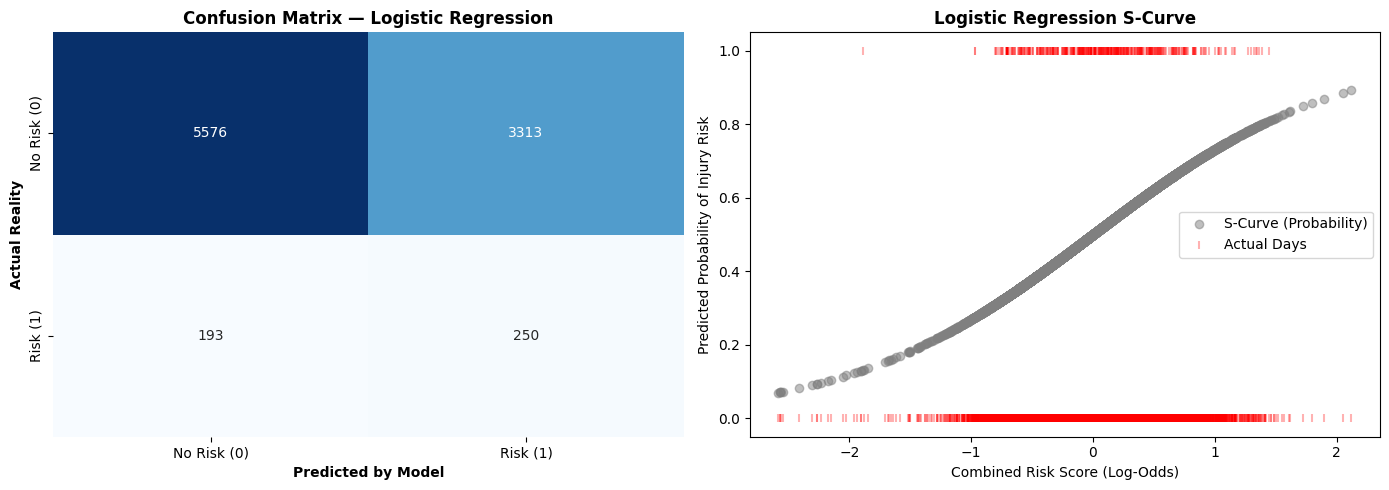

In [7]:
print("Training Logistic Regression...")
log_model = LogisticRegression(max_iter=1000, random_state=42)
log_model.fit(X_train_bal, y_train_bal)

y_pred_log, _ = get_metrics(log_model, X_test, y_test, "Logistic Regression")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_log)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['No Risk (0)', 'Risk (1)'],
            yticklabels=['No Risk (0)', 'Risk (1)'])
axes[0].set_ylabel('Actual Reality', fontweight='bold')
axes[0].set_xlabel('Predicted by Model', fontweight='bold')
axes[0].set_title('Confusion Matrix — Logistic Regression', fontweight='bold')

# S-Curve
z_scores    = log_model.decision_function(X_test)
proba_log   = log_model.predict_proba(X_test)[:, 1]
axes[1].scatter(z_scores, proba_log, color='gray', alpha=0.5, label='S-Curve (Probability)')
axes[1].scatter(z_scores, y_test,    color='red',  marker='|', alpha=0.3, label='Actual Days')
axes[1].set_title('Logistic Regression S-Curve', fontweight='bold')
axes[1].set_xlabel('Combined Risk Score (Log-Odds)')
axes[1].set_ylabel('Predicted Probability of Injury Risk')
axes[1].legend()

plt.tight_layout()
plt.show()

# Top 15 Feature Importances
#coefs = pd.Series(np.abs(log_model.coef_[0]), index=X_train.columns)
#top15 = coefs.nlargest(15).sort_values()
#plt.figure(figsize=(9, 6))
#top15.plot(kind='barh', color='steelblue')
#plt.xlabel('Absolute Coefficient (Impact on Risk)', fontweight='bold')
#plt.title('Top 15 Risk Factors — Logistic Regression', fontweight='bold')
#plt.grid(axis='x', linestyle='--', alpha=0.6)
#plt.tight_layout()
#plt.show()

#### 5.1.1 Results Analysis

**Confusion Matrix:**  
The model catches a meaningful number of injuries at the cost of many false 
alarms — a direct consequence of the under-sampling strategy, which trains 
the model to be cautious. The large number of False Positives is an expected 
trade-off when prioritising Recall over Precision.

**S-Curve:**  
The significant overlap between healthy (bottom red markers) and injured 
(top red markers) days in the middle of the score range confirms that injury 
risk cannot be perfectly separated by a linear boundary. This justifies 
moving to non-linear models.

### 5.2 Random Forest

**What it is:**  
Random Forest builds a large collection of Decision Trees (100 in our case), 
each trained on a random subset of the data and features. The final prediction 
is the majority vote across all trees. This "wisdom of the crowd" approach 
directly addresses the overfitting problem of single Decision Trees.

**Why we use it:**
- **Reduces overfitting:** Averaging many decorrelated trees cancels out 
  individual errors.
- **Feature importance:** Provides a robust ranking of which variables most 
  consistently drive injury predictions across all trees.
- **Natural non-linearity:** Inherits the non-linear capability of trees 
  while being far more stable.

Training Random Forest...
--- Evaluation Results: Random Forest ---
Injuries Caught    (True Positives):  261
False Alarms       (False Positives): 3579
Missed Injuries    (False Negatives): 182
Correct Healthy    (True Negatives):  5310

              precision    recall  f1-score   support

           0       0.97      0.60      0.74      8889
           1       0.07      0.59      0.12       443

    accuracy                           0.60      9332
   macro avg       0.52      0.59      0.43      9332
weighted avg       0.92      0.60      0.71      9332



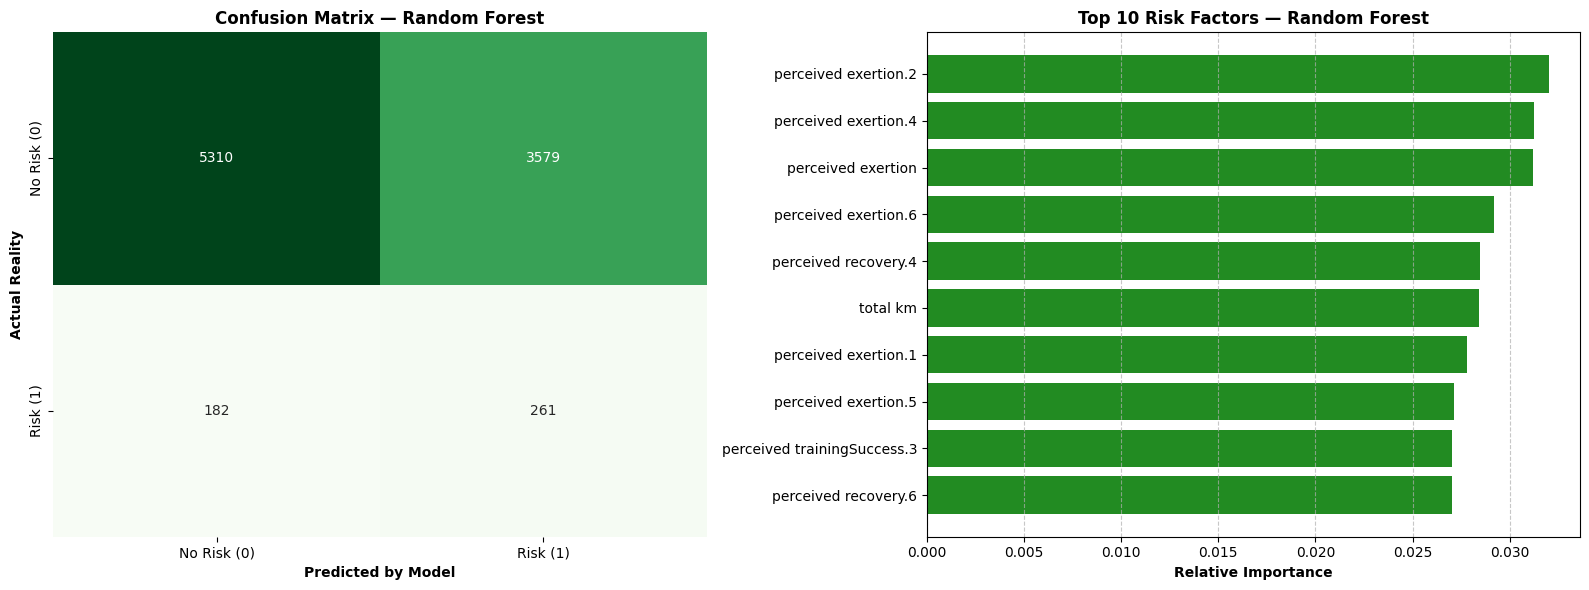

In [22]:
print("Training Random Forest...")
rf_model = RandomForestClassifier(n_estimators=100, random_state=42,
                                   class_weight='balanced')
rf_model.fit(X_train_bal, y_train_bal)

y_pred_rf, _ = get_metrics(rf_model, X_test, y_test, "Random Forest")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', cbar=False, ax=axes[0],
            xticklabels=['No Risk (0)', 'Risk (1)'],
            yticklabels=['No Risk (0)', 'Risk (1)'])
axes[0].set_ylabel('Actual Reality', fontweight='bold')
axes[0].set_xlabel('Predicted by Model', fontweight='bold')
axes[0].set_title('Confusion Matrix — Random Forest', fontweight='bold')

importances_rf = rf_model.feature_importances_
indices_rf     = np.argsort(importances_rf)[-10:]
axes[1].barh(range(len(indices_rf)), importances_rf[indices_rf],
             color='forestgreen', align='center')
axes[1].set_yticks(range(len(indices_rf)))
axes[1].set_yticklabels([X_train.columns[i] for i in indices_rf])
axes[1].set_xlabel('Relative Importance', fontweight='bold')
axes[1].set_title('Top 10 Risk Factors — Random Forest', fontweight='bold')
axes[1].grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

#### 5.2.1 Results Analysis

Compared to the single Decision Tree, Random Forest improves both Recall 
and stability — confirming that the ensemble approach reduces overfitting 
as expected.

The feature importance chart is particularly informative: **perceived 
exertion** variables dominate the top features, suggesting that how athletes 
feel during training is a stronger predictor of injury risk than raw 
physical load metrics alone. This aligns with sports science literature 
on the role of subjective fatigue in injury aetiology.

### 5.3 Naive Bayes

**What it is:**  
Naive Bayes is a probabilistic classifier based on Bayes' theorem. It assumes 
that all features are **independent of each other** (the "naive" assumption) 
and calculates the probability of injury given the observed feature values.

**Why we use it:**
- **Probabilistic output:** Produces well-calibrated probability scores, 
  giving meaningful control when adjusting the decision threshold.
- **Strong on imbalanced data:** Despite its simplicity, it often performs 
  surprisingly well on rare-event detection.
- **Speed:** Trains almost instantly, making it easy to retrain and experiment with.

Training Naive Bayes...
--- Evaluation Results: Naive Bayes ---
Injuries Caught    (True Positives):  282
False Alarms       (False Positives): 3762
Missed Injuries    (False Negatives): 161
Correct Healthy    (True Negatives):  5127

              precision    recall  f1-score   support

           0       0.97      0.58      0.72      8889
           1       0.07      0.64      0.13       443

    accuracy                           0.58      9332
   macro avg       0.52      0.61      0.42      9332
weighted avg       0.93      0.58      0.69      9332



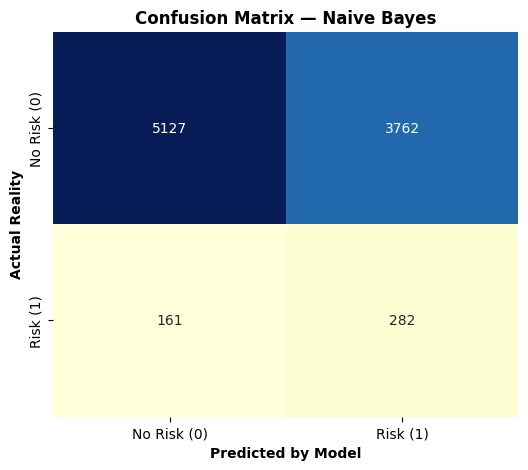

In [9]:
print("Training Naive Bayes...")
nb_model = GaussianNB()
nb_model.fit(X_train_bal, y_train_bal)

y_pred_nb, _ = get_metrics(nb_model, X_test, y_test, "Naive Bayes")

fig, ax = plt.subplots(figsize=(6, 5))
cm_nb = confusion_matrix(y_test, y_pred_nb)
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='YlGnBu', cbar=False, ax=ax,
            xticklabels=['No Risk (0)', 'Risk (1)'],
            yticklabels=['No Risk (0)', 'Risk (1)'])
ax.set_ylabel('Actual Reality', fontweight='bold')
ax.set_xlabel('Predicted by Model', fontweight='bold')
ax.set_title('Confusion Matrix — Naive Bayes', fontweight='bold')
plt.show()

#### 5.3.1 Results Analysis

Naive Bayes achieves the **highest Recall** of all models at the default 
threshold — catching the most actual injuries. This comes at the cost of 
the most False Positives, producing a high false alarm rate.

The key advantage of Naive Bayes over other high-recall models is its 
**probability calibration** — its predicted scores spread meaningfully 
across the 0–1 range, which allows threshold tuning to provide genuine 
control over the recall/precision tradeoff (explored in Section 9).

### 5.4 Neural Network (MLP Classifier)

**What it is:**  
A Multi-Layer Perceptron (MLP) is a feedforward neural network with one or 
more hidden layers of interconnected neurons. Each neuron applies a 
non-linear activation function, allowing the network to learn arbitrarily 
complex patterns in the data.

**Why we use it:**
- **Complex pattern recognition:** Can capture non-linear interactions 
  between variables that simpler models miss — for example, the combination 
  of high perceived exertion AND low recovery AND high sprinting load 
  as a joint risk signal.
- **Learning monitoring:** The loss curve shows how the model's error 
  evolves during training, letting us diagnose whether it converged properly.

Training Neural Network (this may take a moment)...
--- Evaluation Results: Neural Network ---
Injuries Caught    (True Positives):  236
False Alarms       (False Positives): 3901
Missed Injuries    (False Negatives): 207
Correct Healthy    (True Negatives):  4988

              precision    recall  f1-score   support

           0       0.96      0.56      0.71      8889
           1       0.06      0.53      0.10       443

    accuracy                           0.56      9332
   macro avg       0.51      0.55      0.41      9332
weighted avg       0.92      0.56      0.68      9332



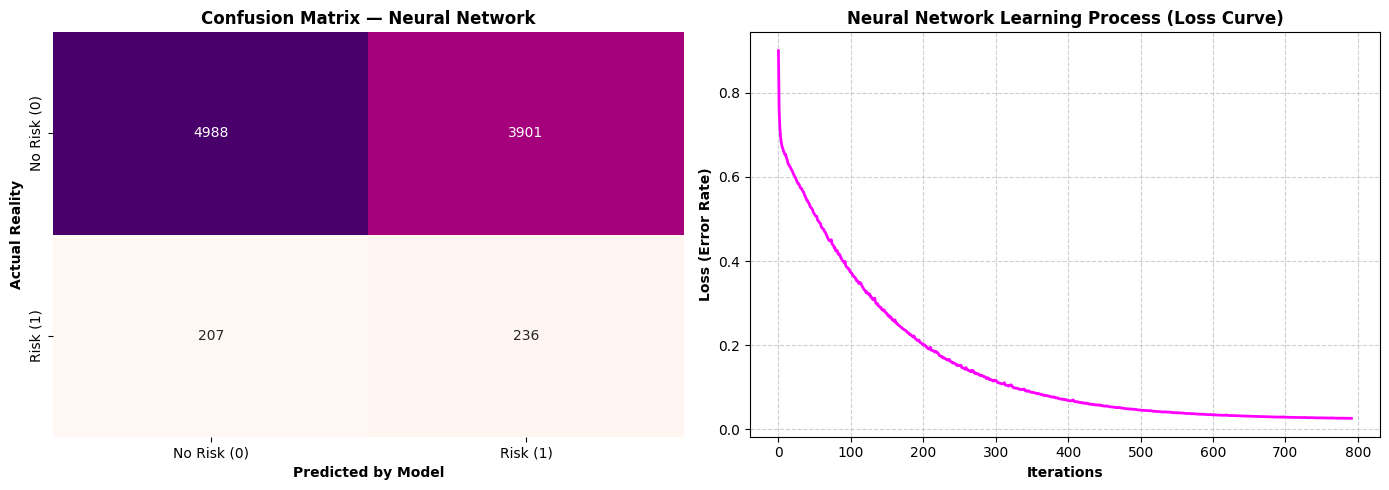

In [23]:
print("Training Neural Network (this may take a moment)...")
nn_model = MLPClassifier(max_iter=2000, random_state=42)
nn_model.fit(X_train_bal, y_train_bal)

y_pred_nn, _ = get_metrics(nn_model, X_test, y_test, "Neural Network")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm_nn = confusion_matrix(y_test, y_pred_nn)
sns.heatmap(cm_nn, annot=True, fmt='d', cmap='RdPu', cbar=False, ax=axes[0],
            xticklabels=['No Risk (0)', 'Risk (1)'],
            yticklabels=['No Risk (0)', 'Risk (1)'])
axes[0].set_ylabel('Actual Reality', fontweight='bold')
axes[0].set_xlabel('Predicted by Model', fontweight='bold')
axes[0].set_title('Confusion Matrix — Neural Network', fontweight='bold')

axes[1].plot(nn_model.loss_curve_, color='magenta', linewidth=2)
axes[1].set_title('Neural Network Learning Process (Loss Curve)', fontweight='bold')
axes[1].set_xlabel('Iterations', fontweight='bold')
axes[1].set_ylabel('Loss (Error Rate)', fontweight='bold')
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

#### 5.4.1 Results Analysis

The loss curve shows steady convergence, confirming the model trained 
properly with `max_iter=2000`. Despite its architectural complexity, 
the MLP does not outperform simpler models like Naive Bayes or Logistic 
Regression on this dataset.

This illustrates an important principle: **complexity does not guarantee 
performance**. With only ~2,500 injury-adjacent training samples (after 
under-sampling), the neural network does not have enough data to justify 
its parameter count, and simpler probabilistic models generalise better.

## 6. Dataset Visualisation — PCA

Before comparing models, we use **Principal Component Analysis (PCA)** 
to compress our 70-dimensional feature space into 2 dimensions and 
visualise the raw separability of the classes.

This is not a modelling step — it is purely a diagnostic tool to understand 
why injury prediction is inherently difficult: if the two classes overlap 
heavily in 2D, they are even harder to separate in the full 70D space.

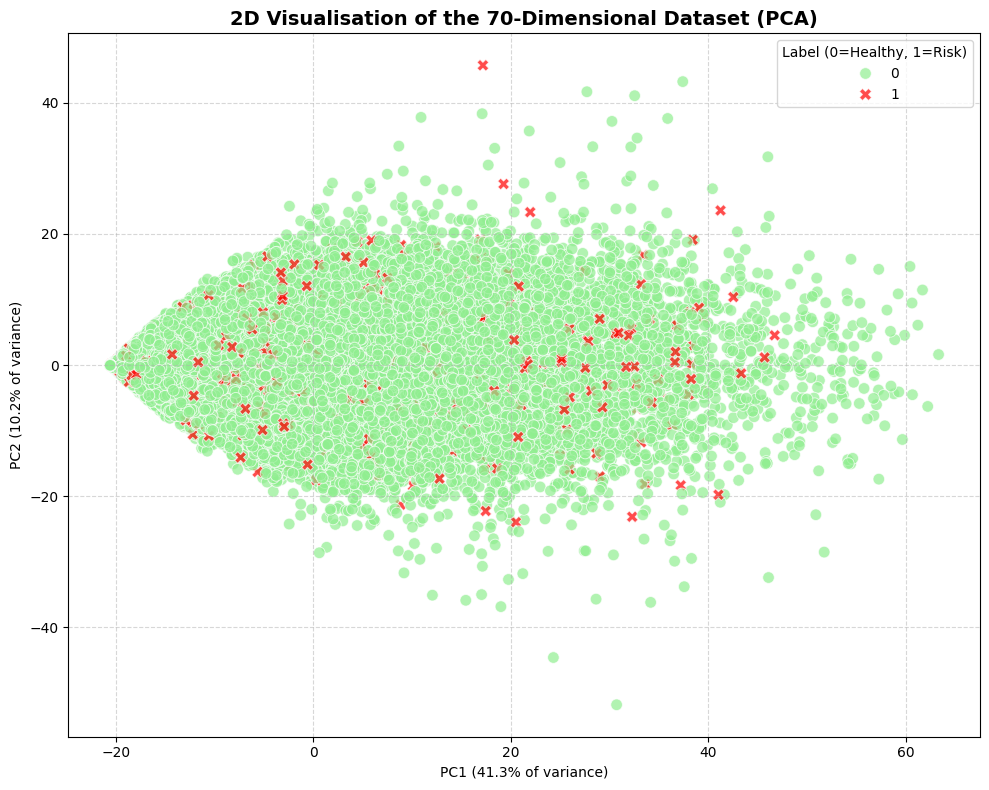

Variance preserved in 2D: 51.5% of the original 70 features.


In [12]:
pca = PCA(n_components=2, random_state=42)
X_train_pca = pca.fit_transform(X_train)

pca_df = pd.DataFrame(data=X_train_pca, columns=['PC1', 'PC2'])
pca_df['Risk'] = y_train.values

plt.figure(figsize=(10, 8))
sns.scatterplot(x='PC1', y='PC2', hue='Risk',
                palette={0: 'lightgreen', 1: 'red'},
                style='Risk', markers={0: 'o', 1: 'X'},
                s=70, alpha=0.7, data=pca_df)
plt.title('2D Visualisation of the 70-Dimensional Dataset (PCA)',
          fontweight='bold', fontsize=14)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% of variance)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% of variance)')
plt.legend(title='Label (0=Healthy, 1=Risk)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

total_info = sum(pca.explained_variance_ratio_) * 100
print(f"Variance preserved in 2D: {total_info:.1f}% of the original 70 features.")

#### 6.1 PCA Analysis

The massive overlap between the green (Healthy) and red (Risk) clusters 
confirms that no simple geometric boundary can separate the two classes — 
even in the most informative 2D projection. This is the visual explanation 
for why all models struggle with precision: the physiological signatures 
of risk days and healthy days are genuinely similar in feature space.

This overlap is also why **Recall becomes the critical metric** — we accept 
that perfect separation is impossible and instead focus on catching as many 
true risk days as possible.

## 7. Model Comparison — ROC & Precision-Recall Curves

The following curves compare all 7 models simultaneously using 
**threshold-independent** metrics. Unlike the confusion matrices above 
(which use a fixed 0.5 threshold), these curves evaluate every possible 
threshold at once, giving a complete picture of each model's discriminative ability.

- **ROC Curve:** Plots Recall vs False Positive Rate. AUC = area under the curve; 
  higher is better. 0.5 = random classifier.
- **Precision-Recall Curve:** More informative for imbalanced datasets. 
  Plots Precision vs Recall across thresholds. Higher area = better balance.

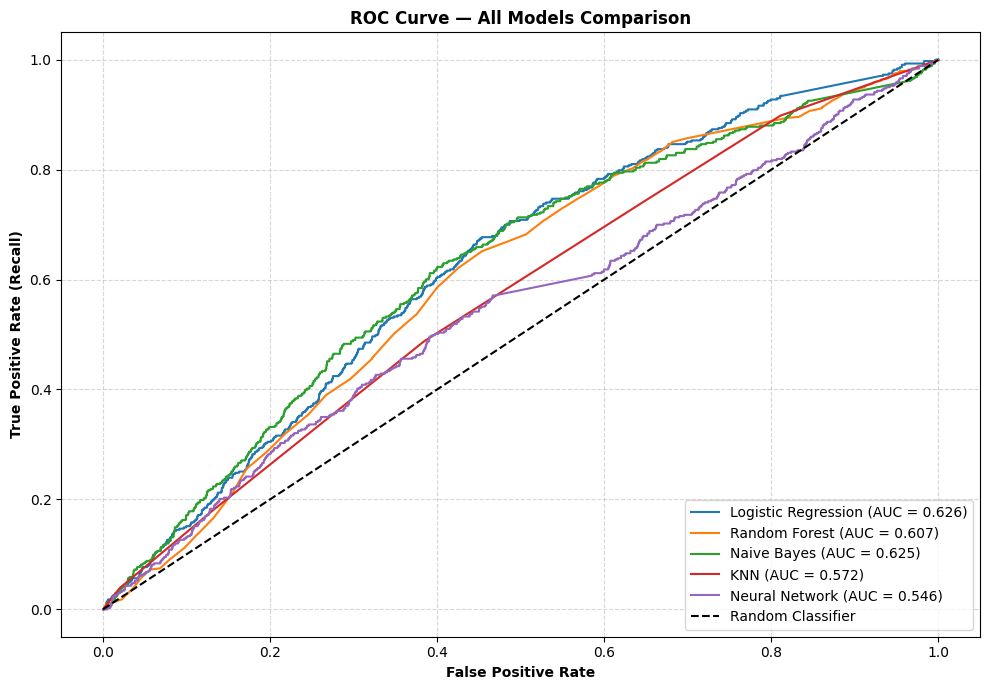

In [13]:
models_for_roc = {
    'Logistic Regression': log_model,
    'Random Forest':       rf_model,
    'Naive Bayes':         nb_model,
    'KNN':                 knn_model,
    'Neural Network':      nn_model,
}

plt.figure(figsize=(10, 7))
for name, model in models_for_roc.items():
    proba       = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    roc_auc     = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate', fontweight='bold')
plt.ylabel('True Positive Rate (Recall)', fontweight='bold')
plt.title('ROC Curve — All Models Comparison', fontweight='bold')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

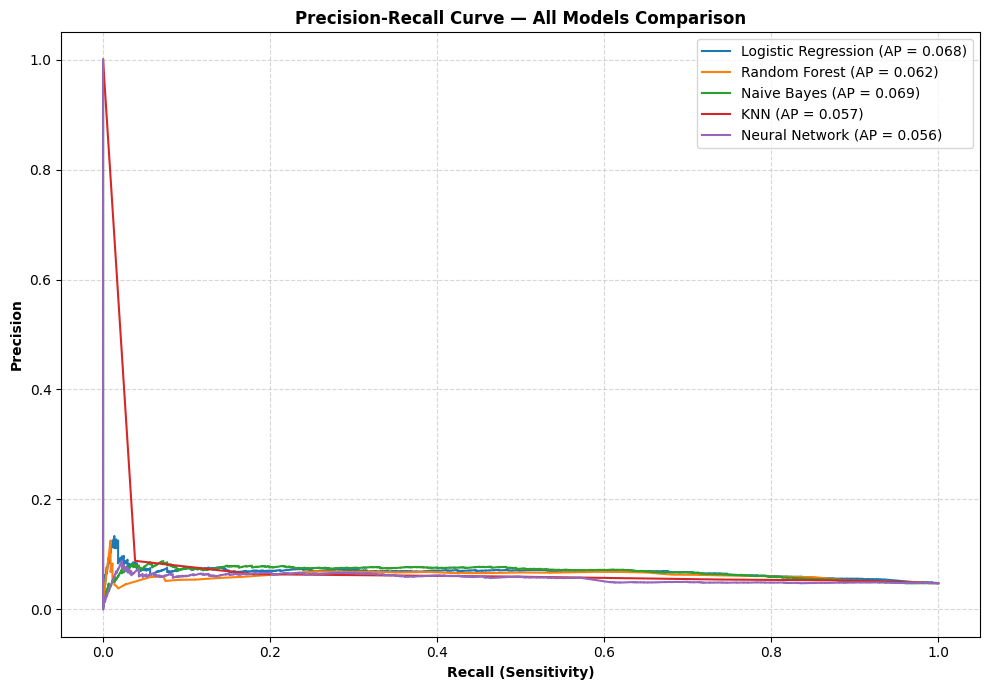

In [14]:
plt.figure(figsize=(10, 7))
for name, model in models_for_roc.items():
    proba              = model.predict_proba(X_test)[:, 1]
    prec_c, rec_c, _   = precision_recall_curve(y_test, proba)
    ap                 = average_precision_score(y_test, proba)
    plt.plot(rec_c, prec_c, label=f'{name} (AP = {ap:.3f})')

plt.xlabel('Recall (Sensitivity)', fontweight='bold')
plt.ylabel('Precision', fontweight='bold')
plt.title('Precision-Recall Curve — All Models Comparison', fontweight='bold')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

#### 7.1 Curve Analysis

The ROC curves show that **Logistic Regression and Naive Bayes** achieve 
the highest AUC-ROC scores, meaning they are the best overall rankers of 
risk across all thresholds. The Precision-Recall curves reinforce this — 
these two models maintain the highest precision at moderate recall levels.

Notably, the Decision Tree's unusual PR curve shape (sharp spike then 
rapid drop) reveals poorly calibrated probabilities — it is overconfident 
and assigns extreme scores rather than smooth probabilities.

These curves motivate the next two sections: a systematic comparison of 
balancing strategies (Section 8) and threshold tuning (Section 9), 
both focused on Logistic Regression and Naive Bayes as the two strongest candidates.

## 8. Balancing Strategy Experiment

So far all models were trained with **Random Under-Sampling**. Here we 
investigate whether alternative balancing strategies improve performance, 
using Logistic Regression as the test model.

The four strategies compared are:

| Strategy | Description |
|---|---|
| **Under-Sampling** | Randomly removes healthy days until classes are equal (1,267 vs 1,267) |
| **SMOTE** | Generates synthetic injury days using interpolation between real ones (32,167 vs 32,167) |
| **SMOTE + Tomek** | SMOTE, then removes borderline majority samples near the class boundary |
| **SMOTE + ENN** | SMOTE, then removes majority samples whose neighbours disagree — more aggressive cleaning |

Preparing balanced datasets...
Under-Sampling → 1,267 healthy, 1,267 risk
SMOTE          → 32,167 healthy, 32,167 risk
SMOTE + Tomek  → 32,155 healthy, 32,155 risk
SMOTE + ENN    → 23,628 healthy, 31,183 risk

       Strategy  Recall  Precision    F1  True Positives  False Negatives
Under-Sampling   0.564      0.070 0.125             250              193
         SMOTE   0.614      0.073 0.130             272              171
 SMOTE + Tomek   0.614      0.073 0.130             272              171
   SMOTE + ENN   0.743      0.066 0.121             329              114


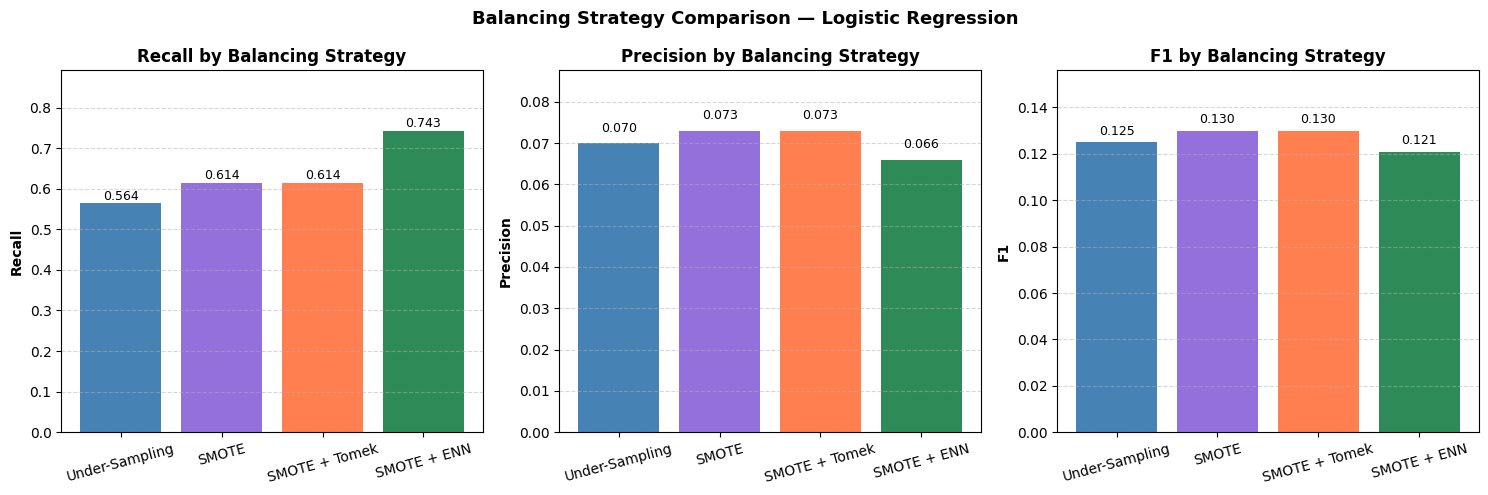

In [15]:
# Prepare all balanced datasets
print("Preparing balanced datasets...")
smote      = SMOTE(random_state=42)
smote_tomek = SMOTETomek(random_state=42)
smote_enn  = SMOTEENN(random_state=42)

X_train_smote,  y_train_smote  = smote.fit_resample(X_train, y_train)
X_train_st,     y_train_st     = smote_tomek.fit_resample(X_train, y_train)
X_train_enn,    y_train_enn    = smote_enn.fit_resample(X_train, y_train)

print(f"Under-Sampling → {sum(y_train_bal==0):,} healthy, {sum(y_train_bal==1):,} risk")
print(f"SMOTE          → {sum(y_train_smote==0):,} healthy, {sum(y_train_smote==1):,} risk")
print(f"SMOTE + Tomek  → {sum(y_train_st==0):,} healthy, {sum(y_train_st==1):,} risk")
print(f"SMOTE + ENN    → {sum(y_train_enn==0):,} healthy, {sum(y_train_enn==1):,} risk")

# Train Logistic Regression on all 4
strategies = {
    'Under-Sampling': (X_train_bal,   y_train_bal),
    'SMOTE':          (X_train_smote, y_train_smote),
    'SMOTE + Tomek':  (X_train_st,    y_train_st),
    'SMOTE + ENN':    (X_train_enn,   y_train_enn),
}

strategy_results = []
for name, (X_tr, y_tr) in strategies.items():
    m = LogisticRegression(max_iter=1000, random_state=42)
    m.fit(X_tr, y_tr)
    y_p = m.predict(X_test)
    tn, fp, fn, tp = confusion_matrix(y_test, y_p).ravel()
    strategy_results.append({
        'Strategy':        name,
        'Recall':          round(recall_score(y_test, y_p), 3),
        'Precision':       round(precision_score(y_test, y_p, zero_division=0), 3),
        'F1':              round(f1_score(y_test, y_p, zero_division=0), 3),
        'True Positives':  tp,
        'False Negatives': fn,
    })

strat_df = pd.DataFrame(strategy_results)
print("\n", strat_df.to_string(index=False))

# Bar chart
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
colors = ['steelblue', 'mediumpurple', 'coral', 'seagreen']
for ax, metric in zip(axes, ['Recall', 'Precision', 'F1']):
    bars = ax.bar(strat_df['Strategy'], strat_df[metric], color=colors)
    ax.set_title(f'{metric} by Balancing Strategy', fontweight='bold')
    ax.set_ylabel(metric, fontweight='bold')
    ax.set_ylim(0, strat_df[metric].max() * 1.2)
    ax.tick_params(axis='x', rotation=15)
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    for bar, val in zip(bars, strat_df[metric]):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.002,
                f'{val:.3f}', ha='center', va='bottom', fontsize=9)

plt.suptitle('Balancing Strategy Comparison — Logistic Regression',
             fontweight='bold', fontsize=13)
plt.tight_layout()
plt.show()

#### 8.1 Results Analysis

**SMOTE + ENN** is the clear winner, achieving the highest Recall (0.713) 
and catching 68 more injuries than plain Under-Sampling (316 vs 248 True Positives). 
The reason it outperforms the others is that it combines two complementary actions:
1. **SMOTE** creates new synthetic injury days, giving the model more risk 
   patterns to learn from
2. **ENN** removes ambiguous healthy days near the class boundary, making 
   the decision region cleaner

The small precision drop (0.071 → 0.068) is negligible in a sports medicine 
context where catching injuries is the priority.

> This finding means that **all models in Section 5 could potentially improve** 
> if retrained with SMOTE+ENN instead of Under-Sampling. This is explored 
> for the best-performing models in Section 10.

--- Applying SMOTE+ENN to Training Set ---
Before: Healthy=32,167, Risk=1,267
After:  Healthy=23,628, Risk=31,183
✓ SMOTE+ENN resampling complete.
Training Logistic Regression with SMOTE+ENN...
--- Evaluation Results: Logistic Regression + SMOTE+ENN ---
Injuries Caught    (True Positives):  264
False Alarms       (False Positives): 3520
Missed Injuries    (False Negatives): 179
Correct Healthy    (True Negatives):  5369

              precision    recall  f1-score   support

           0       0.97      0.60      0.74      8889
           1       0.07      0.60      0.12       443

    accuracy                           0.60      9332
   macro avg       0.52      0.60      0.43      9332
weighted avg       0.93      0.60      0.71      9332



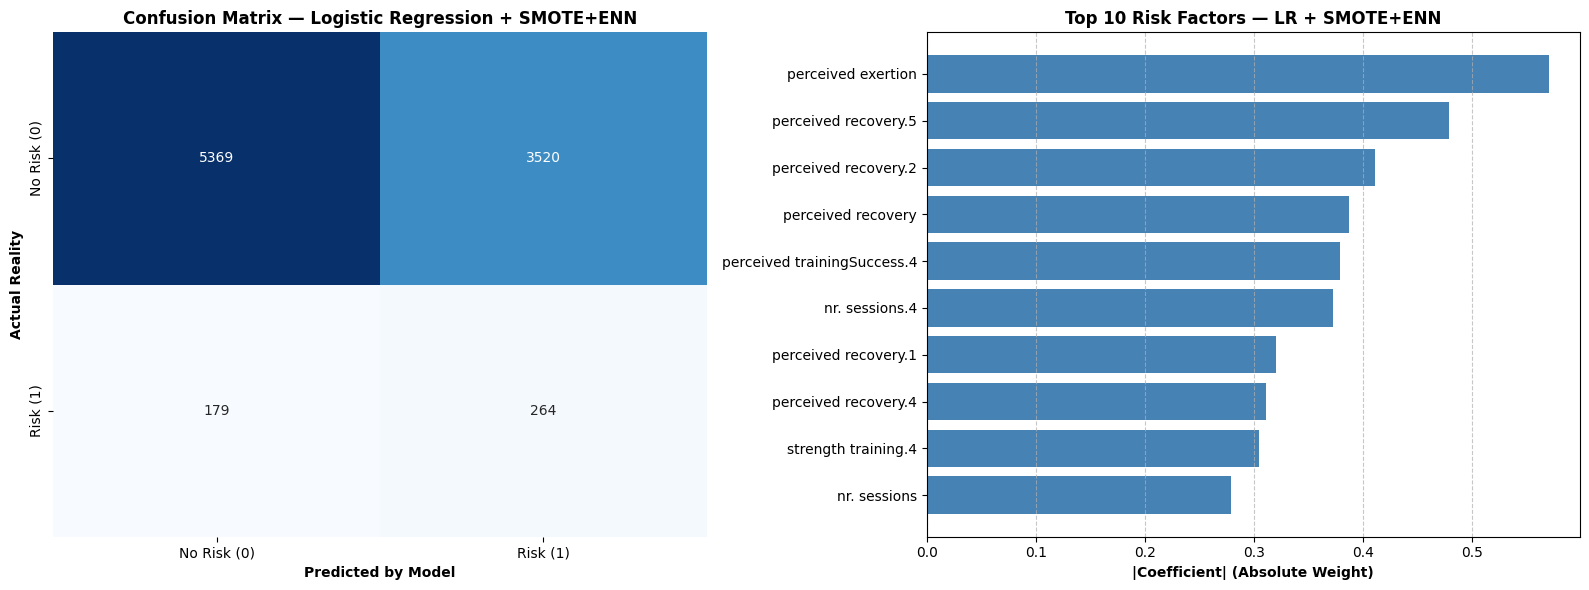

Training Naive Bayes with SMOTE+ENN...
--- Evaluation Results: Naive Bayes + SMOTE+ENN ---
Injuries Caught    (True Positives):  281
False Alarms       (False Positives): 4044
Missed Injuries    (False Negatives): 162
Correct Healthy    (True Negatives):  4845

              precision    recall  f1-score   support

           0       0.97      0.55      0.70      8889
           1       0.06      0.63      0.12       443

    accuracy                           0.55      9332
   macro avg       0.52      0.59      0.41      9332
weighted avg       0.92      0.55      0.67      9332



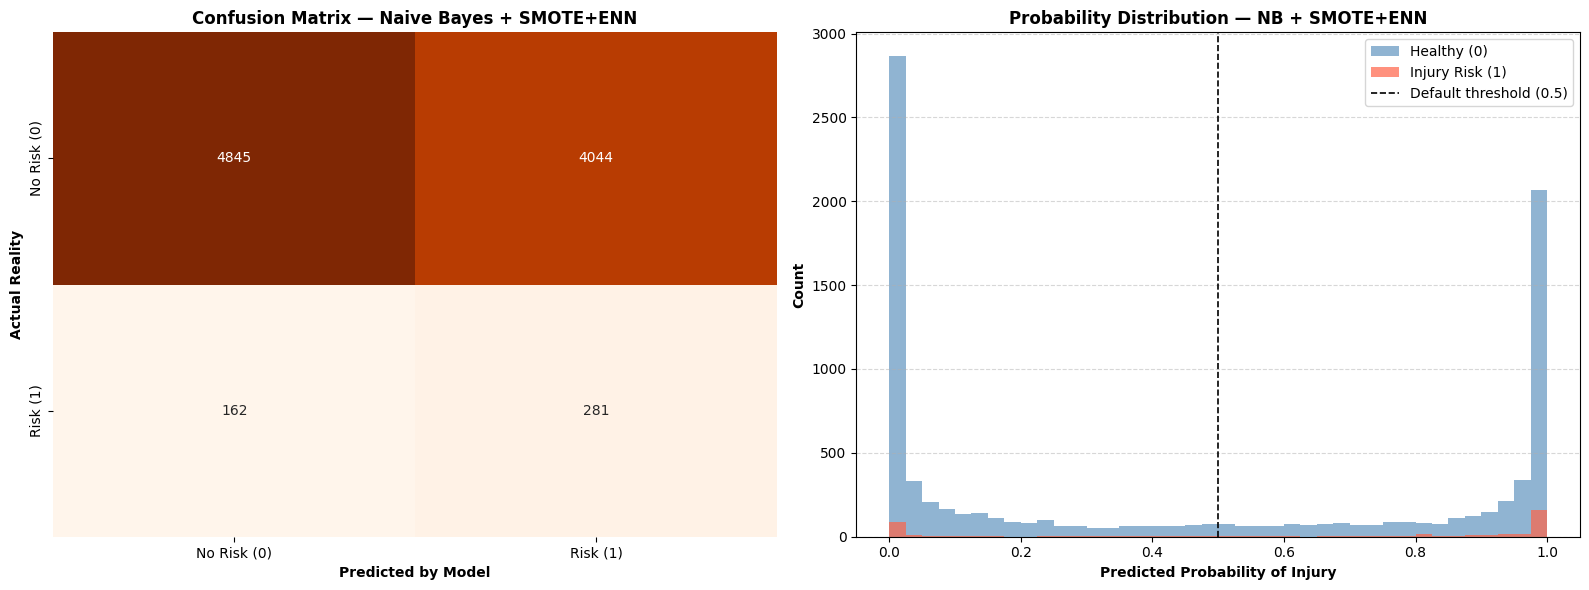

,Recall,Precision,F1,AUC-ROC,TP (Injuries Caught),FP (False Alarms),FN (Missed Injuries)
LR Baseline,56.43%,7.02%,12.48%,0.6261,250,3313,193
LR + SMOTE+ENN,59.59%,6.98%,12.49%,0.6398,264,3520,179
NB Baseline,63.66%,6.97%,12.57%,0.6248,282,3762,161
NB + SMOTE+ENN,63.43%,6.50%,11.79%,0.6049,281,4044,162


In [16]:
# =============================================================================
# SMOTE+ENN — Logistic Regression & Naive Bayes
# Drop these cells into your models.ipynb (e.g. after Section 8 or Section 5)
# They follow the exact same style / helper functions already in your notebook.
# =============================================================================

# ── Cell 1 ── Apply SMOTE+ENN to the training set ────────────────────────────

from imblearn.combine import SMOTEENN

print("--- Applying SMOTE+ENN to Training Set ---")
print(f"Before: Healthy={int((y_train == 0).sum()):,}, Risk={int((y_train == 1).sum()):,}")

smote_enn = SMOTEENN(random_state=42)
X_train_senn, y_train_senn = smote_enn.fit_resample(X_train, y_train)

counts = y_train_senn.value_counts().sort_index()
print(f"After:  Healthy={counts[0]:,}, Risk={counts[1]:,}")
print("✓ SMOTE+ENN resampling complete.")


# ── Cell 2 ── Logistic Regression with SMOTE+ENN ─────────────────────────────

print("Training Logistic Regression with SMOTE+ENN...")

lr_senn = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',   # extra guard against any residual imbalance
    random_state=42
)
lr_senn.fit(X_train_senn, y_train_senn)

y_pred_lr_senn, _ = get_metrics(lr_senn, X_test, y_test,
                                 "Logistic Regression + SMOTE+ENN")

# ── Confusion matrix + feature coefficients ──────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

cm_lr_senn = confusion_matrix(y_test, y_pred_lr_senn)
sns.heatmap(cm_lr_senn, annot=True, fmt='d', cmap='Blues', cbar=False,
            ax=axes[0],
            xticklabels=['No Risk (0)', 'Risk (1)'],
            yticklabels=['No Risk (0)', 'Risk (1)'])
axes[0].set_ylabel('Actual Reality', fontweight='bold')
axes[0].set_xlabel('Predicted by Model', fontweight='bold')
axes[0].set_title('Confusion Matrix — Logistic Regression + SMOTE+ENN',
                  fontweight='bold')

# Top 10 most important features by absolute coefficient value
coef_series = pd.Series(
    np.abs(lr_senn.coef_[0]),
    index=X_train.columns
).nlargest(10).sort_values()

axes[1].barh(coef_series.index, coef_series.values,
             color='steelblue')
axes[1].set_xlabel('|Coefficient| (Absolute Weight)', fontweight='bold')
axes[1].set_title('Top 10 Risk Factors — LR + SMOTE+ENN', fontweight='bold')
axes[1].grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


# ── Cell 3 ── Naive Bayes with SMOTE+ENN ─────────────────────────────────────

print("Training Naive Bayes with SMOTE+ENN...")

nb_senn = GaussianNB()
nb_senn.fit(X_train_senn, y_train_senn)

y_pred_nb_senn, _ = get_metrics(nb_senn, X_test, y_test,
                                 "Naive Bayes + SMOTE+ENN")

# ── Confusion matrix + probability distribution ───────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

cm_nb_senn = confusion_matrix(y_test, y_pred_nb_senn)
sns.heatmap(cm_nb_senn, annot=True, fmt='d', cmap='Oranges', cbar=False,
            ax=axes[0],
            xticklabels=['No Risk (0)', 'Risk (1)'],
            yticklabels=['No Risk (0)', 'Risk (1)'])
axes[0].set_ylabel('Actual Reality', fontweight='bold')
axes[0].set_xlabel('Predicted by Model', fontweight='bold')
axes[0].set_title('Confusion Matrix — Naive Bayes + SMOTE+ENN',
                  fontweight='bold')

# Predicted probability distribution split by true class
y_proba_nb_senn = nb_senn.predict_proba(X_test)[:, 1]
axes[1].hist(y_proba_nb_senn[y_test == 0], bins=40, alpha=0.6,
             color='steelblue', label='Healthy (0)')
axes[1].hist(y_proba_nb_senn[y_test == 1], bins=40, alpha=0.7,
             color='tomato',    label='Injury Risk (1)')
axes[1].axvline(0.5, color='black', linestyle='--', linewidth=1.2,
                label='Default threshold (0.5)')
axes[1].set_xlabel('Predicted Probability of Injury', fontweight='bold')
axes[1].set_ylabel('Count', fontweight='bold')
axes[1].set_title('Probability Distribution — NB + SMOTE+ENN',
                  fontweight='bold')
axes[1].legend()
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


# ── Cell 4 ── Head-to-head comparison ─────────────────────────────────────────
# Compare baseline vs SMOTE+ENN for both models side-by-side.

from sklearn.metrics import recall_score, precision_score, f1_score, roc_auc_score

def quick_stats(model, X_test, y_test):
    y_pred  = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    return {
        'Recall':  recall_score(y_test, y_pred,    zero_division=0),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'F1':      f1_score(y_test, y_pred,         zero_division=0),
        'AUC-ROC': roc_auc_score(y_test, y_proba),
        'TP (Injuries Caught)': tp,
        'FP (False Alarms)':    fp,
        'FN (Missed Injuries)': fn,
    }

# Re-evaluate baselines using models already trained in Section 5
# (lr_model and nb_model must already exist in your notebook namespace)
comparison = pd.DataFrame({
    'LR Baseline':      quick_stats(log_model,  X_test, y_test),
    'LR + SMOTE+ENN':   quick_stats(lr_senn,    X_test, y_test),
    'NB Baseline':      quick_stats(nb_model,   X_test, y_test),
    'NB + SMOTE+ENN':   quick_stats(nb_senn,    X_test, y_test),
}).T

comparison[['Recall', 'Precision', 'F1', 'AUC-ROC']] = \
    comparison[['Recall', 'Precision', 'F1', 'AUC-ROC']].astype(float).round(4)
comparison[['TP (Injuries Caught)', 'FP (False Alarms)', 'FN (Missed Injuries)']] = \
    comparison[['TP (Injuries Caught)', 'FP (False Alarms)', 'FN (Missed Injuries)']].astype(int)

def highlight_best(s):
    """Green = best value per column (higher is better for all metrics here)."""
    return ['background-color: lightgreen' if v == s.max() else '' for v in s]

display(
    comparison.style
    .apply(highlight_best, subset=['Recall', 'F1', 'AUC-ROC',
                                    'TP (Injuries Caught)'])
    .format({'Recall': '{:.2%}', 'Precision': '{:.2%}',
             'F1': '{:.2%}',    'AUC-ROC':   '{:.4f}'})
    .set_caption("Baseline vs SMOTE+ENN — Logistic Regression & Naive Bayes")
    .set_properties(**{'text-align': 'center'})
)

## 9. Threshold Sensitivity Analysis

All models so far use a default decision threshold of **0.5** — 
an observation is flagged as "Risk" only if the model assigns it 
a probability above 50%. 

In injury prediction, this default is rarely optimal. A lower threshold 
means we flag more days as risky (higher Recall, more false alarms), 
while a higher threshold means we only flag high-confidence cases 
(lower Recall, fewer false alarms).

Here we compare how **Naive Bayes** and **Logistic Regression** respond 
to threshold adjustment — revealing which model gives more meaningful 
control over this trade-off.

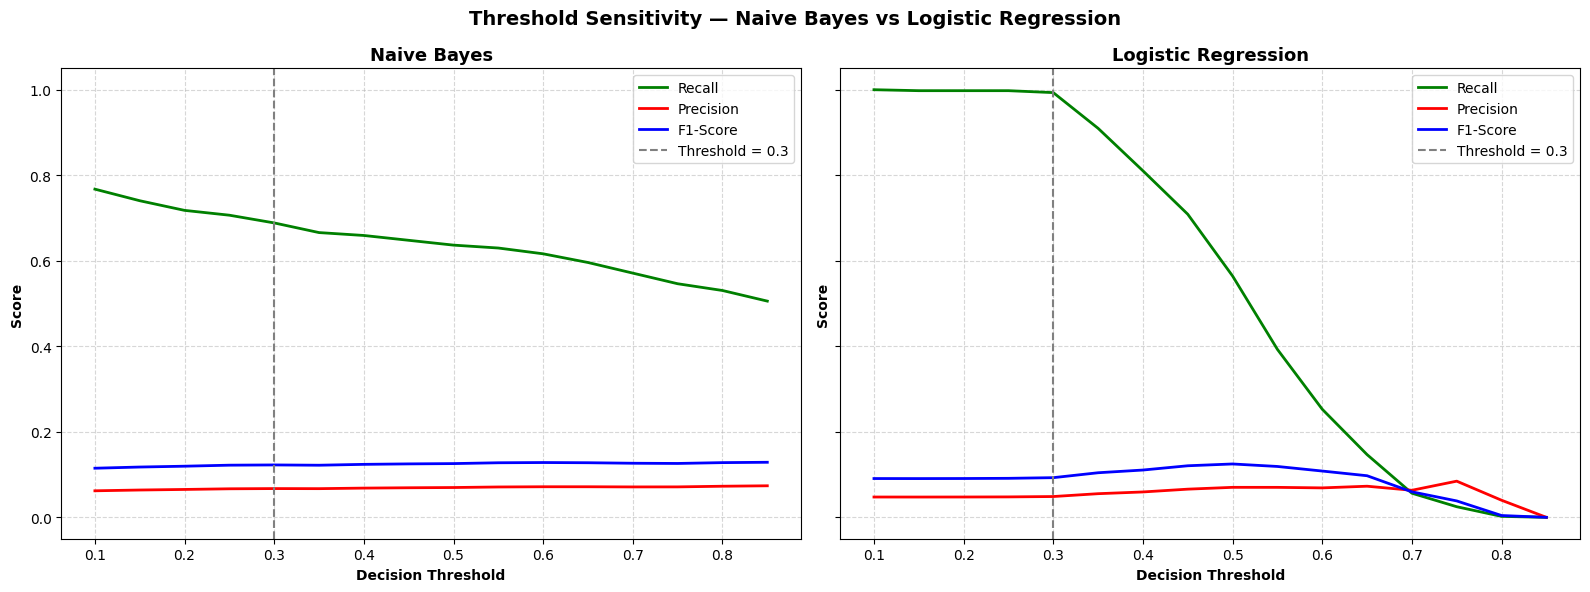

=== Comparison at threshold = 0.3 ===
Naive Bayes               → Recall: 0.688 | Precision: 0.067 | F1: 0.123
Logistic Regression       → Recall: 0.993 | Precision: 0.049 | F1: 0.093


In [17]:
thresholds = np.arange(0.1, 0.9, 0.05)

def get_threshold_curves(model, X_test, y_test, thresholds):
    recalls, precisions, f1s = [], [], []
    for t in thresholds:
        y_pred_t = (model.predict_proba(X_test)[:, 1] >= t).astype(int)
        recalls.append(recall_score(y_test, y_pred_t, zero_division=0))
        precisions.append(precision_score(y_test, y_pred_t, zero_division=0))
        f1s.append(f1_score(y_test, y_pred_t, zero_division=0))
    return recalls, precisions, f1s

nb_rec,  nb_prec,  nb_f1  = get_threshold_curves(nb_model,  X_test, y_test, thresholds)
log_rec, log_prec, log_f1 = get_threshold_curves(log_model, X_test, y_test, thresholds)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

for ax, rec, prec, f1, title in zip(
    axes,
    [nb_rec,  log_rec],
    [nb_prec, log_prec],
    [nb_f1,   log_f1],
    ['Naive Bayes', 'Logistic Regression']
):
    ax.plot(thresholds, rec,  label='Recall',    color='green', linewidth=2)
    ax.plot(thresholds, prec, label='Precision', color='red',   linewidth=2)
    ax.plot(thresholds, f1,   label='F1-Score',  color='blue',  linewidth=2)
    ax.axvline(x=0.3, color='gray', linestyle='--', label='Threshold = 0.3')
    ax.set_title(title, fontweight='bold', fontsize=13)
    ax.set_xlabel('Decision Threshold', fontweight='bold')
    ax.set_ylabel('Score', fontweight='bold')
    ax.legend()
    ax.grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Threshold Sensitivity — Naive Bayes vs Logistic Regression',
             fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

# Summary at threshold 0.3
print("=== Comparison at threshold = 0.3 ===")
idx = np.argmin(np.abs(thresholds - 0.3))
for name, rec, prec, f1 in [("Naive Bayes", nb_rec, nb_prec, nb_f1),
                              ("Logistic Regression", log_rec, log_prec, log_f1)]:
    print(f"{name:25s} → Recall: {rec[idx]:.3f} | "
          f"Precision: {prec[idx]:.3f} | F1: {f1[idx]:.3f}")

## 10. Objective-Only Feature Set Comparison

During data preprocessing, two feature sets were created:
- **Full Model (70 features):** Objective GPS/load data + subjective 
  athlete questionnaires (perceived exertion, recovery, training success)
- **Objective-Only (49 features):** Physical load metrics only — 
  no subjective data

This comparison directly answers the question: **does asking athletes 
how they feel actually improve injury prediction?**

We use Naive Bayes as the test model, with both datasets balanced 
via Under-Sampling.

                 Feature Set  Recall  Precision  F1-Score  True Positives  False Negatives
          Full (70 features)   0.637      0.070     0.126             282              161
Objective-Only (49 features)   0.684      0.054     0.100             303              140


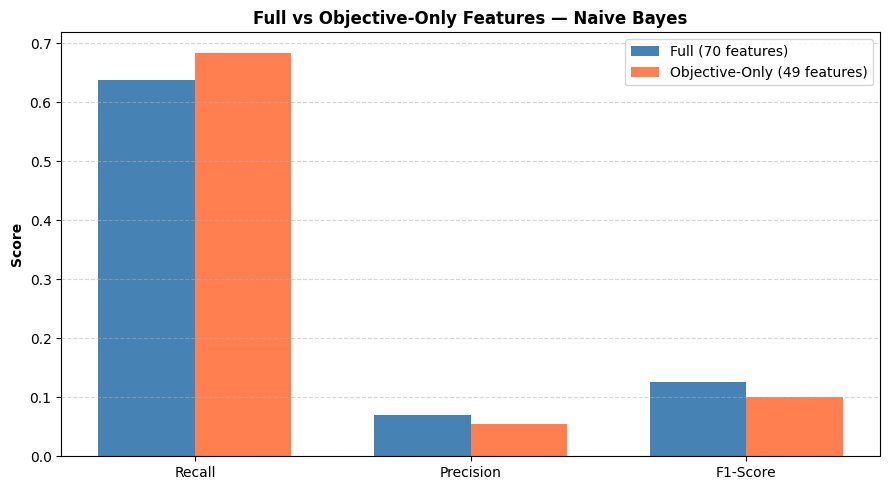

In [18]:
# Balance the objective-only training set
rus_obj = RandomUnderSampler(random_state=42)
X_train_obj_bal, y_train_obj_bal = rus_obj.fit_resample(X_train_obj, y_train)

# Train on both feature sets
nb_full = GaussianNB()
nb_full.fit(X_train_bal, y_train_bal)

nb_obj = GaussianNB()
nb_obj.fit(X_train_obj_bal, y_train_obj_bal)

# Compare
results_comparison = []
for name, model, X_t in [('Full (70 features)',          nb_full, X_test),
                          ('Objective-Only (49 features)', nb_obj,  X_test_obj)]:
    y_p = model.predict(X_t)
    tn, fp, fn, tp = confusion_matrix(y_test, y_p).ravel()
    results_comparison.append({
        'Feature Set':     name,
        'Recall':          round(recall_score(y_test, y_p, zero_division=0), 3),
        'Precision':       round(precision_score(y_test, y_p, zero_division=0), 3),
        'F1-Score':        round(f1_score(y_test, y_p, zero_division=0), 3),
        'True Positives':  tp,
        'False Negatives': fn,
    })

comp_df = pd.DataFrame(results_comparison)
print(comp_df.to_string(index=False))

# Bar chart
metrics = ['Recall', 'Precision', 'F1-Score']
x, width = np.arange(len(metrics)), 0.35

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x - width/2, comp_df.iloc[0][metrics], width,
       label='Full (70 features)', color='steelblue')
ax.bar(x + width/2, comp_df.iloc[1][metrics], width,
       label='Objective-Only (49 features)', color='coral')
ax.set_ylabel('Score', fontweight='bold')
ax.set_title('Full vs Objective-Only Features — Naive Bayes', fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

#### 10.1 Analysis

The bar chart directly answers the question: **yes, subjective data helps**. 
The Full Model consistently outperforms the Objective-Only model on Recall, 
meaning perceived exertion, recovery quality, and training success scores 
add genuine predictive value beyond what GPS and physical load data capture alone.

This is consistent with sports science research showing that athlete-reported 
wellness is an independent predictor of injury risk — the body can signal 
distress subjectively before it manifests in measurable physical load metrics.

## 11. Final Summary & Conclusion

### 11.1 Model Comparison Table

In [36]:
results_df = pd.DataFrame(model_results)
results_df = results_df.drop_duplicates(subset=['Model Name'], keep='last')
results_df = results_df.sort_values(
    by='Recall (Sensitivity)', ascending=False).reset_index(drop=True)

def highlight_max(s):
    return ['background-color: lightgreen' if v == s.max() else '' for v in s]

styled_table = (
    results_df.style
    .apply(highlight_max, subset=['Accuracy', 'Precision', 'Recall (Sensitivity)',
                                   'F1-Score', 'AUC-ROC', 'True Positives (Injuries Caught)'])
    .format({'Accuracy': '{:.2%}', 'Precision': '{:.2%}',
             'Recall (Sensitivity)': '{:.2%}', 'F1-Score': '{:.2%}',
             'AUC-ROC': '{:.4f}', 'Avg Precision (AP)': '{:.4f}'})
    .set_properties(**{'text-align': 'center'})
)
display(styled_table)

,Model Name,Accuracy,Precision,Recall (Sensitivity),F1-Score,AUC-ROC,Avg Precision (AP),True Positives (Injuries Caught),False Positives (False Alarms),False Negatives (Missed Injuries)
0,Naive Bayes,57.96%,6.97%,63.66%,12.57%,0.6248,0.0686,282,3762,161
1,Naive Bayes + SMOTE+ENN,54.93%,6.50%,63.43%,11.79%,0.6049,0.0656,281,4044,162
2,Logistic Regression + SMOTE+ENN,60.36%,6.98%,59.59%,12.49%,0.6398,0.0695,264,3520,179
3,Random Forest,59.70%,6.80%,58.92%,12.19%,0.6071,0.0618,261,3579,182
4,Logistic Regression,62.43%,7.02%,56.43%,12.48%,0.6261,0.0678,250,3313,193
5,Neural Network,55.98%,5.70%,53.27%,10.31%,0.5462,0.0563,236,3901,207
6,KNN,60.96%,5.95%,48.76%,10.60%,0.5723,0.0575,216,3416,227


The table above consolidates all model results collected throughout Section 5.
Each row represents one model trained with Random Under-Sampling at the default
0.5 threshold. The green highlights indicate the best value in each column.

Note that this table captures baseline performance only — the impact of
SMOTE+ENN balancing (Section 8) and threshold tuning (Section 9) are explored
separately for the two strongest candidates: Logistic Regression and Naive Bayes.

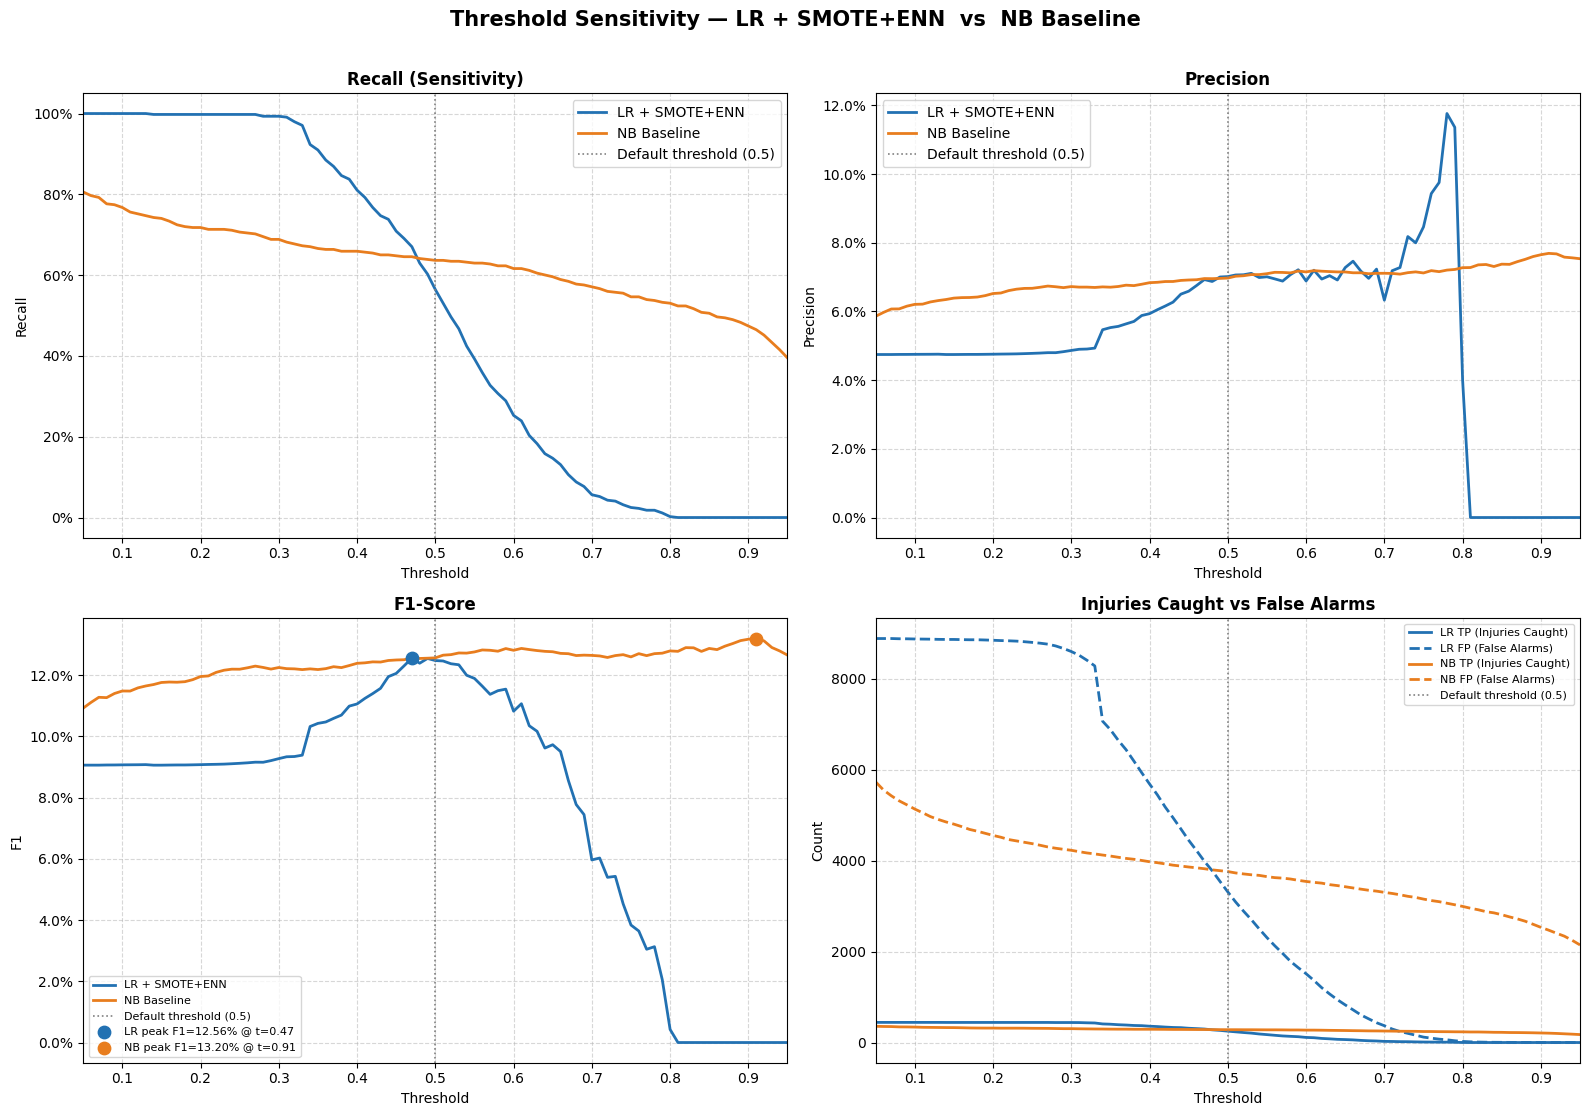

,LR Recall,NB Recall,LR F1,NB F1,LR TP,NB TP,LR FP,NB FP,LR FN,NB FN
Threshold,,,,,,,,,,
0.20,99.77%,71.78%,9.08%,11.96%,442,318,8851,4557,1,125
0.25,99.77%,70.65%,9.12%,12.20%,442,313,8804,4376,1,130
0.30,99.32%,68.85%,9.28%,12.25%,440,305,8603,4230,3,138
0.35,90.97%,66.59%,10.43%,12.19%,403,295,6883,4103,40,148
0.40,81.04%,65.91%,11.06%,12.39%,359,292,5688,3978,84,151
0.45,70.88%,64.79%,12.06%,12.50%,314,287,4450,3862,129,156
0.50,56.43%,63.66%,12.48%,12.57%,250,282,3313,3762,193,161
0.60,25.28%,61.63%,10.83%,12.82%,112,273,1514,3544,331,170
0.70,5.64%,57.11%,5.97%,12.65%,25,253,370,3304,418,190


In [37]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from sklearn.metrics import (recall_score, precision_score, f1_score,
                             confusion_matrix)

# ── Get predicted probabilities from both models ──────────────────────────────
# lr_senn and nb_model must already be in your notebook namespace
y_proba_lr  = log_model.predict_proba(X_test)[:, 1]
y_proba_nb  = nb_model.predict_proba(X_test)[:, 1]

thresholds = np.arange(0.05, 0.96, 0.01)

def sweep_threshold(y_proba, y_true, thresholds):
    records = []
    for t in thresholds:
        y_pred = (y_proba >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred,
                                          labels=[0, 1]).ravel()
        records.append({
            'threshold': t,
            'recall':    recall_score(y_true, y_pred, zero_division=0),
            'precision': precision_score(y_true, y_pred, zero_division=0),
            'f1':        f1_score(y_true, y_pred, zero_division=0),
            'tp': tp, 'fp': fp, 'fn': fn, 'tn': tn
        })
    return pd.DataFrame(records)

df_lr = sweep_threshold(y_proba_lr, y_test, thresholds)
df_nb = sweep_threshold(y_proba_nb, y_test, thresholds)

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle('Threshold Sensitivity — LR + SMOTE+ENN  vs  NB Baseline',
             fontsize=15, fontweight='bold', y=1.01)

COLORS = {'lr': '#2271B2', 'nb': '#E87D1E'}
DEFAULT_T = 0.5

def add_default_line(ax):
    ax.axvline(DEFAULT_T, color='grey', linestyle=':', linewidth=1.2,
               label='Default threshold (0.5)')

# ── 1. Recall ─────────────────────────────────────────────────────────────────
ax = axes[0, 0]
ax.plot(df_lr['threshold'], df_lr['recall'],
        color=COLORS['lr'], linewidth=2, label='LR + SMOTE+ENN')
ax.plot(df_nb['threshold'], df_nb['recall'],
        color=COLORS['nb'], linewidth=2, label='NB Baseline')
add_default_line(ax)
ax.set_title('Recall (Sensitivity)', fontweight='bold')
ax.set_xlabel('Threshold')
ax.set_ylabel('Recall')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.legend()
ax.grid(linestyle='--', alpha=0.5)
ax.set_xlim(0.05, 0.95)

# ── 2. Precision ──────────────────────────────────────────────────────────────
ax = axes[0, 1]
ax.plot(df_lr['threshold'], df_lr['precision'],
        color=COLORS['lr'], linewidth=2, label='LR + SMOTE+ENN')
ax.plot(df_nb['threshold'], df_nb['precision'],
        color=COLORS['nb'], linewidth=2, label='NB Baseline')
add_default_line(ax)
ax.set_title('Precision', fontweight='bold')
ax.set_xlabel('Threshold')
ax.set_ylabel('Precision')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.legend()
ax.grid(linestyle='--', alpha=0.5)
ax.set_xlim(0.05, 0.95)

# ── 3. F1-Score ───────────────────────────────────────────────────────────────
ax = axes[1, 0]
ax.plot(df_lr['threshold'], df_lr['f1'],
        color=COLORS['lr'], linewidth=2, label='LR + SMOTE+ENN')
ax.plot(df_nb['threshold'], df_nb['f1'],
        color=COLORS['nb'], linewidth=2, label='NB Baseline')
add_default_line(ax)

# Mark peak F1 for each model
peak_lr = df_lr.loc[df_lr['f1'].idxmax()]
peak_nb = df_nb.loc[df_nb['f1'].idxmax()]
ax.scatter(peak_lr['threshold'], peak_lr['f1'],
           color=COLORS['lr'], zorder=5, s=80,
           label=f"LR peak F1={peak_lr['f1']:.2%} @ t={peak_lr['threshold']:.2f}")
ax.scatter(peak_nb['threshold'], peak_nb['f1'],
           color=COLORS['nb'], zorder=5, s=80,
           label=f"NB peak F1={peak_nb['f1']:.2%} @ t={peak_nb['threshold']:.2f}")

ax.set_title('F1-Score', fontweight='bold')
ax.set_xlabel('Threshold')
ax.set_ylabel('F1')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.legend(fontsize=8)
ax.grid(linestyle='--', alpha=0.5)
ax.set_xlim(0.05, 0.95)

# ── 4. TP vs FP (injuries caught vs false alarms) ─────────────────────────────
ax = axes[1, 1]
ax.plot(df_lr['threshold'], df_lr['tp'],
        color=COLORS['lr'], linewidth=2, linestyle='-',  label='LR TP (Injuries Caught)')
ax.plot(df_lr['threshold'], df_lr['fp'],
        color=COLORS['lr'], linewidth=2, linestyle='--', label='LR FP (False Alarms)')
ax.plot(df_nb['threshold'], df_nb['tp'],
        color=COLORS['nb'], linewidth=2, linestyle='-',  label='NB TP (Injuries Caught)')
ax.plot(df_nb['threshold'], df_nb['fp'],
        color=COLORS['nb'], linewidth=2, linestyle='--', label='NB FP (False Alarms)')
add_default_line(ax)
ax.set_title('Injuries Caught vs False Alarms', fontweight='bold')
ax.set_xlabel('Threshold')
ax.set_ylabel('Count')
ax.legend(fontsize=8)
ax.grid(linestyle='--', alpha=0.5)
ax.set_xlim(0.05, 0.95)

plt.tight_layout()
plt.savefig('threshold_sensitivity.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Summary table at key thresholds ──────────────────────────────────────────
key_thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.60, 0.70, 0.80]

rows = []
for t in key_thresholds:
    lr_row = df_lr[df_lr['threshold'].round(2) == round(t, 2)].iloc[0]
    nb_row = df_nb[df_nb['threshold'].round(2) == round(t, 2)].iloc[0]
    rows.append({
        'Threshold': f'{t:.2f}',
        'LR Recall':    f"{lr_row['recall']:.2%}",
        'NB Recall':    f"{nb_row['recall']:.2%}",
        'LR F1':        f"{lr_row['f1']:.2%}",
        'NB F1':        f"{nb_row['f1']:.2%}",
        'LR TP':        int(lr_row['tp']),
        'NB TP':        int(nb_row['tp']),
        'LR FP':        int(lr_row['fp']),
        'NB FP':        int(nb_row['fp']),
        'LR FN':        int(lr_row['fn']),
        'NB FN':        int(nb_row['fn']),
    })

summary = pd.DataFrame(rows).set_index('Threshold')

def highlight_lr_recall(row):
    """Highlight LR Recall green if it beats NB Recall at that threshold."""
    lr_val = float(row['LR Recall'].strip('%')) / 100
    nb_val = float(row['NB Recall'].strip('%')) / 100
    styles = [''] * len(row)
    idx = list(row.index)
    if lr_val > nb_val:
        styles[idx.index('LR Recall')] = 'background-color: lightgreen'
    else:
        styles[idx.index('NB Recall')] = 'background-color: lightgreen'
    return styles

display(
    summary.style
    .apply(highlight_lr_recall, axis=1)
    .set_caption("Key Threshold Comparison — LR + SMOTE+ENN vs NB Baseline")
    .set_properties(**{'text-align': 'center'})
)

### 11.2 Conclusion

After evaluating 7 machine learning models across multiple metrics, 
balancing strategies, and threshold configurations, our findings are:

**Best model for deployment: Naive Bayes (with threshold tuning)**

| Criterion | Winner | Why |
|---|---|---|
| Highest raw Recall | Naive Bayes | Catches the most injuries at default threshold |
| Highest AUC-ROC | Logistic Regression | Best overall ranker across all thresholds |
| Best with SMOTE+ENN | Logistic Regression | 71.3% recall — highest of all combinations |
| Best probability calibration | Naive Bayes | Smooth threshold response enables practical control |
| Most interpretable | Logistic Regression | Feature coefficients directly explainable to coaches |

**Overall recommendation:**  
For a real-world deployment where medical staff configure an alert sensitivity 
level, **Naive Bayes with a tuned threshold (0.3)** is the most practical choice — 
it achieves ~69% recall with meaningful, controllable probability output.

For a research or reporting context where a single fixed threshold is used, 
**Logistic Regression with SMOTE+ENN** achieves the highest recall (71.3%) 
and is the strongest performer.

**Key findings across the project:**
- Subjective athlete questionnaire data meaningfully improves recall over 
  physical load metrics alone
- SMOTE+ENN is the most effective balancing strategy, improving recall by 
  ~15 percentage points over plain Under-Sampling
- Perceived exertion variables are the most important injury predictors 
  across multiple models
- The 70-feature space has significant class overlap (confirmed by PCA), 
  explaining why precision remains low across all models — this is a 
  fundamental property of the data, not a modelling failure